# Support Ticket Analysis & Machine Learning

## Project Overview

This project analyzes IT support ticket data to understand ticket characteristics, identify operational patterns, and uncover factors associated with SLA breaches and ticket priority.

The project combines statistical analysis, exploratory data analysis (EDA), data visualization, and machine learning to generate actionable insights and support data-driven decision-making.

## Objectives

- Understand the structure and characteristics of the support ticket dataset.
- Assess data quality and explore key statistical patterns.
- Identify trends and relationships through data visualization.
- Develop and evaluate machine learning models for SLA breach prediction and ticket priority classification.
- Translate analytical findings into actionable recommendations for improving IT support operations.

## Tools & Technologies

Python, Pandas, NumPy, Matplotlib, Seaborn, Scikit-learn, SQL Server, and Jupyter Notebook.

## Workflow

Business Understanding → Data Loading → Data Understanding → Data Quality Assessment → Statistical Analysis → Exploratory Data Analysis & Visualization → Feature Engineering → Machine Learning → Model Evaluation → Key Findings & Recommendations.

01 — Setup & Data Loading

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import pyodbc
import sqlalchemy

print("All libraries are ready!")
print("Pandas:", pd.__version__)
print("Scikit-learn:", sklearn.__version__)
print("SQL Server ODBC drivers:", pyodbc.drivers())

All libraries are ready!
Pandas: 3.0.6
Scikit-learn: 1.9.1
SQL Server ODBC drivers: ['SQL Server', 'SQL Server Native Client RDA 11.0', 'SQL Anywhere 17', 'SQL Server Native Client 11.0', 'ODBC Driver 17 for SQL Server', 'ODBC Driver 18 for SQL Server']


In [2]:
import pyodbc
import pandas as pd

server = r".\SQL2025"
database = "IT_Solution_DWH"

conn_str = (
    "DRIVER={ODBC Driver 18 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
    "TrustServerCertificate=yes;"
)

conn = pyodbc.connect(conn_str)

print("Connected successfully!")
print("Database:", database)

conn.close()

Connected successfully!
Database: IT_Solution_DWH


In [3]:
conn = pyodbc.connect(conn_str)

schema_df = pd.read_sql_query("""
    SELECT
        TABLE_SCHEMA,
        TABLE_NAME,
        COLUMN_NAME,
        DATA_TYPE,
        ORDINAL_POSITION
    FROM INFORMATION_SCHEMA.COLUMNS
    WHERE TABLE_SCHEMA = 'Gold'
    ORDER BY TABLE_NAME, ORDINAL_POSITION
""", conn)

display(schema_df)

conn.close()

C:\Users\samar\AppData\Local\Temp\ipykernel_23208\235732649.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  schema_df = pd.read_sql_query("""


,TABLE_SCHEMA,TABLE_NAME,COLUMN_NAME,DATA_TYPE,ORDINAL_POSITION
0,Gold,DimCustomer,CustomerKey,bigint,1
1,Gold,DimCustomer,CustomerName,nvarchar,2
2,Gold,DimCustomer,CustomerEmail,nvarchar,3
3,Gold,DimCustomer,CustomerAge,int,4
4,Gold,DimCustomer,CustomerGender,nvarchar,5
5,Gold,DimCustomer,SubscriptionType,nvarchar,6
6,Gold,DimCustomer,CustomerTenureMonths,int,7
7,Gold,DimCustomer,CustomerSegment,nvarchar,8
8,Gold,DimDate,DateKey,int,1
9,Gold,DimDate,FullDate,date,2


In [6]:
import pandas as pd
import pyodbc

conn = pyodbc.connect(conn_str)

queries = {
    "Priority": """
        SELECT s.Priority AS Category, COUNT_BIG(*) AS [TicketCount]
        FROM Gold.FactTickets f
        JOIN Gold.DimTicketState s
          ON f.TicketStateKey = s.TicketStateKey
        GROUP BY s.Priority
        ORDER BY [TicketCount] DESC
    """,
    "Status": """
        SELECT s.Status AS Category, COUNT_BIG(*) AS [TicketCount]
        FROM Gold.FactTickets f
        JOIN Gold.DimTicketState s
          ON f.TicketStateKey = s.TicketStateKey
        GROUP BY s.Status
        ORDER BY [TicketCount] DESC
    """,
    "Issue Category": """
        SELECT i.Category AS Category, COUNT_BIG(*) AS [TicketCount]
        FROM Gold.FactTickets f
        JOIN Gold.DimIssue i
          ON f.IssueKey = i.IssueKey
        GROUP BY i.Category
        ORDER BY [TicketCount] DESC
    """,
    "SLA Breach": """
        SELECT fl.SlaBreached AS Category, COUNT_BIG(*) AS [TicketCount]
        FROM Gold.FactTickets f
        JOIN Gold.DimTicketFlags fl
          ON f.FlagsKey = fl.FlagsKey
        GROUP BY fl.SlaBreached
        ORDER BY [TicketCount] DESC
    """,
    "Escalation": """
        SELECT fl.escalated AS Category, COUNT_BIG(*) AS [TicketCount]
        FROM Gold.FactTickets f
        JOIN Gold.DimTicketFlags fl
          ON f.FlagsKey = fl.FlagsKey
        GROUP BY fl.escalated
        ORDER BY [TicketCount] DESC
    """
}

try:
    for title, query in queries.items():
        print(f"\n--- {title} Distribution ---")
        result_df = pd.read_sql_query(query, conn)
        display(result_df)
finally:
    conn.close()


--- Priority Distribution ---


C:\Users\samar\AppData\Local\Temp\ipykernel_23208\3810051238.py:52: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result_df = pd.read_sql_query(query, conn)


,Category,TicketCount
0,Medium,350258
1,Low,291414
2,High,279106
3,Urgent,127797



--- Status Distribution ---


C:\Users\samar\AppData\Local\Temp\ipykernel_23208\3810051238.py:52: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result_df = pd.read_sql_query(query, conn)


...

C:\Users\samar\AppData\Local\Temp\ipykernel_23208\3810051238.py:52: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result_df = pd.read_sql_query(query, conn)


,Category,TicketCount
0,No,543076
1,Yes,398430
2,NaN,107069



--- Escalation Distribution ---


C:\Users\samar\AppData\Local\Temp\ipykernel_23208\3810051238.py:52: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  result_df = pd.read_sql_query(query, conn)


,Category,TicketCount
0,No,648216
1,Yes,293388
2,Unknown,106971


In [5]:

import pandas as pd
import pyodbc
import time
import gc

query = """
SELECT
    f.TicketKey,
    f.TicketId,
    d_created.FullDate AS created_at,

    s.Status AS status,
    s.Priority AS priority,

    i.Category AS category,
    i.IssueType AS issue_type,

    c.CustomerAge AS customer_age,
    c.CustomerGender AS customer_gender,
    c.CustomerTenureMonths AS customer_tenure_months,
    c.CustomerSegment AS customer_segment,
    c.SubscriptionType AS subscription_type,

    ctx.product,
    ctx.channel,
    ctx.region,
    ctx.language,

    flags.escalated,
    flags.SlaBreached AS sla_breached,

    f.SlaTargetHours AS sla_target_hours,
    f.SlaBreachMarginMinutes AS sla_breach_margin_minutes,
    f.CustomerSatisfactionScore AS customer_satisfaction_score,

    f.FirstResponseTimeMinutes / 60.0
        AS first_response_time_hours,
    f.ResolutionTimeMinutes / 60.0
        AS resolution_time_hours,
    f.ResolutionWallclockMinutes / 60.0
        AS resolution_wallclock_hours,
    f.PausedMinutes / 60.0 AS paused_hours,

    f.ReopenCount AS reopen_count,
    f.IssueComplexityScore AS issue_complexity_score

FROM Gold.FactTickets AS f

LEFT JOIN Gold.DimDate AS d_created
    ON f.CreatedAtKey = d_created.DateKey

LEFT JOIN Gold.DimTicketState AS s
    ON f.TicketStateKey = s.TicketStateKey

LEFT JOIN Gold.DimIssue AS i
    ON f.IssueKey = i.IssueKey

LEFT JOIN Gold.DimCustomer AS c
    ON f.CustomerKey = c.CustomerKey

LEFT JOIN Gold.DimTicketContext AS ctx
    ON f.TicketContextKey = ctx.TicketContextKey

LEFT JOIN Gold.DimTicketFlags AS flags
    ON f.FlagsKey = flags.FlagsKey
"""

chunks = []
start_time = time.time()
loaded_rows = 0

conn = pyodbc.connect(conn_str, timeout=60)

try:
    for chunk in pd.read_sql_query(
        query,
        conn,
        chunksize=25_000
    ):
        chunks.append(chunk)
        loaded_rows += len(chunk)

        print(
            f"Loaded {loaded_rows:,} rows | "
            f"Elapsed: {(time.time() - start_time) / 60:.1f} min"
        )
finally:
    conn.close()

df = pd.concat(chunks, ignore_index=True)
del chunks
gc.collect()

df["created_at"] = pd.to_datetime(
    df["created_at"], errors="coerce"
)

print("\nData loaded successfully!")
print("Shape:", df.shape)
print(
    "Memory usage:",
    round(df.memory_usage(deep=True).sum() / (1024**3), 2),
    "GB"
)

display(df.head())


C:\Users\samar\AppData\Local\Temp\ipykernel_23208\3918507500.py:75: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  for chunk in pd.read_sql_query(


Loaded 25,000 rows | Elapsed: 2.9 min
Loaded 50,000 rows | Elapsed: 2.9 min
Loaded 75,000 rows | Elapsed: 2.9 min
Loaded 100,000 rows | Elapsed: 2.9 min
Loaded 125,000 rows | Elapsed: 3.0 min
Loaded 150,000 rows | Elapsed: 3.0 min
Loaded 175,000 rows | Elapsed: 3.0 min
Loaded 200,000 rows | Elapsed: 3.0 min
Loaded 225,000 rows | Elapsed: 3.0 min
Loaded 250,000 rows | Elapsed: 3.0 min
Loaded 275,000 rows | Elapsed: 3.1 min
Loaded 300,000 rows | Elapsed: 3.1 min
Loaded 325,000 rows | Elapsed: 3.1 min
Loaded 350,000 rows | Elapsed: 3.1 min
Loaded 375,000 rows | Elapsed: 3.1 min
Loaded 400,000 rows | Elapsed: 3.1 min
Loaded 425,000 rows | Elapsed: 3.2 min
Loaded 450,000 rows | Elapsed: 3.2 min
Loaded 475,000 rows | Elapsed: 3.2 min
Loaded 500,000 rows | Elapsed: 3.2 min
Loaded 525,000 rows | Elapsed: 3.2 min
Loaded 550,000 rows | Elapsed: 3.2 min
Loaded 575,000 rows | Elapsed: 3.3 min
Loaded 600,000 rows | Elapsed: 3.3 min
Loaded 625,000 rows | Elapsed: 3.3 min
Loaded 650,000 rows | Elapse

,TicketKey,TicketId,created_at,status,priority,category,issue_type,customer_age,customer_gender,customer_tenure_months,...,sla_breached,sla_target_hours,sla_breach_margin_minutes,customer_satisfaction_score,first_response_time_hours,resolution_time_hours,resolution_wallclock_hours,paused_hours,reopen_count,issue_complexity_score
0,1,1,2023-01-12,Closed,Low,Authentication & Access,authentication_twofa_not_delivered,32,Female,62,...,No,120,6665.0,4.0,0.233333,0.783333,8.916666,0.000000,0,1
1,2,2,2024-09-03,Closed,Low,Integrations & API,integrations_api_docs_request,34,Male,7,...,No,120,7182.0,4.0,0.083333,0.316666,0.300000,0.000000,0,1
2,3,3,2023-06-15,Open,Low,Authentication & Access,authentication_twofa_not_delivered,36,Male,27,...,NaN,120,NaN,NaN,0.116666,NaN,NaN,0.000000,0,2
3,4,4,2022-12-15,Closed,Medium,Subscription,subscription_unexpected_renewal,20,Female,1,...,No,72,3082.0,3.0,3.333333,5.583333,20.633333,0.000000,0,6
4,5,5,2024-01-10,Closed,Low,Integrations & API,integrations_data_export_api,31,Male,40,...,No,120,5466.0,4.0,0.450000,1.500000,28.900000,23.566666,0,4


02 — Data Understanding & Quality Assessment

In [ ]:
# 1. Dataset Overview

print(f"Number of Rows: {df.shape[0]:,}")
print(f"Number of Columns: {df.shape[1]}")

# 2. Data Types
display(
    df.dtypes.rename("Data Type").to_frame()
)

# 3. Missing Values
missing_summary = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage (%)": (
        df.isna().mean() * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    "Missing Percentage (%)",
    ascending=False
)

display(missing_summary)

# 4. Duplicate Checks
print(
    "Duplicate TicketKey:",
    df["TicketKey"].duplicated().sum()
)

print(
    "Duplicate TicketId:",
    df["TicketId"].duplicated().sum()
)

# 5. Basic Statistical Summary
display(df.describe().T)

Number of Rows: 1,048,575
Number of Columns: 27


,Data Type
TicketKey,int64
TicketId,int64
created_at,datetime64[s]
status,str
priority,str
category,str
issue_type,str
customer_age,int64
customer_gender,str
customer_tenure_months,int64


,Missing Count,Missing Percentage (%)
customer_satisfaction_score,107827,10.28
sla_breached,107069,10.21
sla_breach_margin_minutes,106971,10.20
resolution_time_hours,106971,10.20
resolution_wallclock_hours,106971,10.20
category,0,0.00
priority,0,0.00
status,0,0.00
TicketKey,0,0.00
TicketId,0,0.00


Duplicate TicketKey: 0
Duplicate TicketId: 0


,count,mean,min,25%,50%,75%,max,std
TicketKey,1048575.0,524288.0,1.0,262144.5,524288.0,786431.5,1048575.0,302697.673595
TicketId,1048575.0,524288.0,1.0,262144.5,524288.0,786431.5,1048575.0,302697.673595
created_at,1048575,2023-08-31 05:16:40,2022-01-01 00:00:00,2023-01-03 00:00:00,2023-09-29 00:00:00,2024-05-17 00:00:00,2024-12-30 00:00:00,NaN
customer_age,1048575.0,45.994075,18.0,32.0,46.0,60.0,74.0,16.454652
customer_tenure_months,1048575.0,35.491905,0.0,17.0,36.0,53.0,71.0,20.778906
sla_target_hours,1048575.0,64.275791,4.0,24.0,72.0,120.0,120.0,41.922332
sla_breach_margin_minutes,941604.0,-1691.271154,-107858.0,-3220.0,693.0,4024.0,7197.0,9645.089891
customer_satisfaction_score,940748.0,3.624063,1.0,3.0,4.0,4.0,5.0,1.032803
first_response_time_hours,1048575.0,3.066078,0.016666,0.183333,0.45,2.433333,150.45,6.884433
resolution_time_hours,941604.0,13.157922,0.05,0.733333,1.983333,10.483333,7160.783333,57.760697


In [8]:

# Basic Dataset Overview

print("Dataset Shape:", df.shape)
print("Total Tickets:", f"{len(df):,}")
print("Total Columns:", len(df.columns))

print("\nMissing Values:")
display(
    df.isna().sum()
    .sort_values(ascending=False)
    .to_frame("Missing Count")
)

print("\nDuplicate Rows:", f"{df.duplicated().sum():,}")

print("\nTicket Status Distribution:")
display(df["status"].value_counts())

print("\nPriority Distribution:")
display(df["priority"].value_counts())

print("\nTicket Categories:")
display(df["category"].value_counts())


Dataset Shape: (1048575, 27)
Total Tickets: 1,048,575
Total Columns: 27

Missing Values:


,Missing Count
customer_satisfaction_score,107827
sla_breached,107069
sla_breach_margin_minutes,106971
resolution_time_hours,106971
resolution_wallclock_hours,106971
category,0
priority,0
status,0
TicketKey,0
TicketId,0



Duplicate Rows: 0

Ticket Status Distribution:


status
Closed       937144
Open          48358
Cancelled     39308
Pending       11261
On-Hold        7528
Resolved       4460
New             516
Name: count, dtype: int64


Priority Distribution:


priority
Medium    350258
Low       291414
High      279106
Urgent    127797
Name: count, dtype: int64


Ticket Categories:


category
Onboarding & How-To        104852
Account Management         103884
Billing                    101628
Data Sync                  100571
Subscription                96577
Security                    92811
Authentication & Access     92297
Integrations & API          91561
Refunds                     89441
Performance                 88236
Bugs & Errors               86717
Name: count, dtype: int64

03 — Statistical Analysis

In [ ]:

# 3.1 — Descriptive Statistics & Statistical Testing

from scipy.stats import kruskal

# 1. First Response Time
print("First Response Time (hours)")
display(df["first_response_time_hours"].describe().round(2).to_frame())

# 2. Resolution Time
print("\nResolution Time (hours)")
display(df["resolution_time_hours"].describe().round(2).to_frame())

# 3. Customer Satisfaction
print("\nCustomer Satisfaction")
display(df["customer_satisfaction_score"].describe().round(2).to_frame())

# 4. Customer Satisfaction by Priority
print("\nCustomer Satisfaction by Priority")

satisfaction_by_priority = (
    df.groupby("priority")["customer_satisfaction_score"]
    .agg(["count", "mean", "median", "std"])
    .round(2)
)

display(satisfaction_by_priority)

# 5. Kruskal-Wallis Test
# Compare customer satisfaction across priority groups

satisfaction_groups = [
    group["customer_satisfaction_score"].dropna().to_numpy()
    for _, group in df.groupby("priority")
]

satisfaction_groups = [
    group for group in satisfaction_groups if len(group) > 0
]

if len(satisfaction_groups) >= 2:
    statistic, p_value = kruskal(*satisfaction_groups)

    n = sum(len(group) for group in satisfaction_groups)
    k = len(satisfaction_groups)

    epsilon_squared = max(
        0,
        (statistic - k + 1) / (n - k)
    )

    print("\nKruskal-Wallis Test Results")
    print("---------------------------")
    print(f"H-statistic: {statistic:.4f}")
    print(f"P-value: {p_value:.6g}")
    print(f"Epsilon-squared: {epsilon_squared:.6f}")

    if p_value < 0.05:
        print(
            "Result: Satisfaction differs statistically "
            "across at least two priority groups."
        )
    else:
        print(
            "Result: No statistically significant difference "
            "was detected across priority groups."
        )
else:
    print("Not enough valid groups to perform the test.")


First Response Time (hours)


,first_response_time_hours
count,1048575.00
mean,3.07
std,6.88
min,0.02
25%,0.18
50%,0.45
75%,2.43
max,150.45



Resolution Time (hours)


,resolution_time_hours
count,941604.00
mean,13.16
std,57.76
min,0.05
25%,0.73
50%,1.98
75%,10.48
max,7160.78



Customer Satisfaction


,customer_satisfaction_score
count,940748.00
mean,3.62
std,1.03
min,1.00
25%,3.00
50%,4.00
75%,4.00
max,5.00



Customer Satisfaction by Priority


,count,mean,median,std
priority,,,,
High,250514,3.42,3.0,1.05
Low,261342,3.98,4.0,0.88
Medium,314192,3.68,4.0,0.98
Urgent,114700,3.09,3.0,1.12



Kruskal-Wallis Test Results
---------------------------
H-statistic: 68175.6557
P-value: 0
Epsilon-squared: 0.072467
Result: Satisfaction differs statistically across at least two priority groups.


In [10]:

# 3.2 — Support Performance by Category and Priority

def calculate_performance(group):
    valid_sla = group["sla_breached"].isin(["Yes", "No"])
    valid_escalation = group["escalated"].isin(["Yes", "No"])

    return pd.Series({
        "Ticket_Count": len(group),

        "SLA_Breach_Rate_%": (
            group.loc[valid_sla, "sla_breached"].eq("Yes").mean() * 100
            if valid_sla.any() else np.nan
        ),

        "Escalation_Rate_%": (
            group.loc[valid_escalation, "escalated"].eq("Yes").mean() * 100
            if valid_escalation.any() else np.nan
        ),

        "Median_First_Response_Hours":
            group["first_response_time_hours"].median(),

        "Median_Resolution_Hours":
            group["resolution_time_hours"].median(),

        "Avg_Customer_Satisfaction":
            group["customer_satisfaction_score"].mean(),

        "Satisfaction_Records":
            group["customer_satisfaction_score"].count()
    })

category_performance = (
    df.groupby("category")
      .apply(calculate_performance)
      .reset_index()
)

priority_performance = (
    df.groupby("priority")
      .apply(calculate_performance)
      .reset_index()
)

numeric_columns = [
    "SLA_Breach_Rate_%",
    "Escalation_Rate_%",
    "Median_First_Response_Hours",
    "Median_Resolution_Hours",
    "Avg_Customer_Satisfaction"
]

category_performance[numeric_columns] = (
    category_performance[numeric_columns].round(2)
)

priority_performance[numeric_columns] = (
    priority_performance[numeric_columns].round(2)
)

print("Performance by Category — Highest SLA Breach First")
display(
    category_performance.sort_values(
        "SLA_Breach_Rate_%", ascending=False
    ).reset_index(drop=True)
)

print("Performance by Priority — Highest SLA Breach First")
display(
    priority_performance.sort_values(
        "SLA_Breach_Rate_%", ascending=False
    ).reset_index(drop=True)
)


Performance by Category — Highest SLA Breach First


,category,Ticket_Count,SLA_Breach_Rate_%,Escalation_Rate_%,Median_First_Response_Hours,Median_Resolution_Hours,Avg_Customer_Satisfaction,Satisfaction_Records
0,Refunds,89441.0,63.63,59.68,2.43,11.58,3.20,80316.0
1,Security,92811.0,59.78,56.20,1.62,6.98,3.20,83181.0
2,Bugs & Errors,86717.0,56.72,39.42,1.08,4.93,3.40,77755.0
3,Performance,88236.0,41.59,28.18,0.68,3.08,3.60,79206.0
4,Data Sync,100571.0,41.27,23.77,0.45,1.80,3.66,90162.0
5,Authentication & Access,92297.0,39.87,28.04,0.45,1.50,3.70,82808.0
6,Billing,101628.0,39.78,28.30,0.45,1.50,3.67,91136.0
7,Subscription,96577.0,38.40,34.03,0.45,1.50,3.65,86852.0
8,Integrations & API,91561.0,35.53,15.26,0.45,1.50,3.79,82146.0
9,Account Management,103884.0,33.67,20.75,0.27,0.93,3.85,93275.0


Performance by Priority — Highest SLA Breach First


,priority,Ticket_Count,SLA_Breach_Rate_%,Escalation_Rate_%,Median_First_Response_Hours,Median_Resolution_Hours,Avg_Customer_Satisfaction,Satisfaction_Records
0,Urgent,127797.0,83.80,48.19,0.62,2.68,3.09,114700.0
1,High,279106.0,58.82,41.45,0.90,3.87,3.42,250514.0
2,Medium,350258.0,34.45,30.00,0.52,2.55,3.68,314192.0
3,Low,291414.0,17.76,15.22,0.32,1.10,3.98,261342.0


In [11]:

# 3.3 — Monthly Support Performance

monthly_df = df.copy()

monthly_df["month"] = (
    monthly_df["created_at"]
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_performance = (
    monthly_df.groupby("month")
    .agg(
        Ticket_Count=("TicketKey", "count"),
        SLA_Records=(
            "sla_breached",
            lambda x: x.isin(["Yes", "No"]).sum()
        ),
        SLA_Breaches=(
            "sla_breached",
            lambda x: x.eq("Yes").sum()
        ),
        Escalation_Records=(
            "escalated",
            lambda x: x.isin(["Yes", "No"]).sum()
        ),
        Escalated_Tickets=(
            "escalated",
            lambda x: x.eq("Yes").sum()
        ),
        Median_First_Response_Hours=(
            "first_response_time_hours", "median"
        ),
        Median_Resolution_Hours=(
            "resolution_time_hours", "median"
        ),
        Avg_Customer_Satisfaction=(
            "customer_satisfaction_score", "mean"
        )
    )
    .reset_index()
)

monthly_performance["SLA_Breach_Rate_%"] = (
    monthly_performance["SLA_Breaches"]
    / monthly_performance["SLA_Records"].replace(0, np.nan)
    * 100
)

monthly_performance["Escalation_Rate_%"] = (
    monthly_performance["Escalated_Tickets"]
    / monthly_performance["Escalation_Records"].replace(0, np.nan)
    * 100
)

numeric_columns = [
    "SLA_Breach_Rate_%",
    "Escalation_Rate_%",
    "Median_First_Response_Hours",
    "Median_Resolution_Hours",
    "Avg_Customer_Satisfaction"
]

monthly_performance[numeric_columns] = (
    monthly_performance[numeric_columns].round(2)
)

display(monthly_performance)

,month,Ticket_Count,SLA_Records,SLA_Breaches,Escalation_Records,Escalated_Tickets,Median_First_Response_Hours,Median_Resolution_Hours,Avg_Customer_Satisfaction,SLA_Breach_Rate_%,Escalation_Rate_%
0,2022-01-01,19782,18053,7598,18053,5612,0.45,1.97,3.63,42.09,31.09
1,2022-02-01,20010,18263,7797,18266,5631,0.45,1.97,3.62,42.69,30.83
2,2022-03-01,23735,21714,9095,21719,6789,0.45,1.97,3.63,41.89,31.26
3,2022-04-01,22327,20402,8860,20407,6321,0.45,1.98,3.62,43.43,30.97
4,2022-05-01,22941,20872,8778,20873,6553,0.45,2.03,3.62,42.06,31.39
5,2022-06-01,21807,19845,8481,19846,6217,0.45,2.03,3.62,42.74,31.33
6,2022-07-01,20088,18292,7897,18295,5651,0.45,1.90,3.63,43.17,30.89
7,2022-08-01,20515,18753,7895,18755,5992,0.45,2.03,3.61,42.10,31.95
8,2022-09-01,19680,17977,7640,17978,5613,0.45,2.03,3.63,42.50,31.22
9,2022-10-01,20534,18816,7936,18816,5858,0.45,1.93,3.63,42.18,31.13


In [12]:

# 3.4 — Ticket Complexity Analysis

complexity_summary = (
    df.groupby("issue_complexity_score")
    .agg(
        Ticket_Count=("TicketKey", "count"),

        Median_First_Response_Hours=(
            "first_response_time_hours", "median"
        ),

        Median_Resolution_Hours=(
            "resolution_time_hours", "median"
        ),

        Avg_Customer_Satisfaction=(
            "customer_satisfaction_score", "mean"
        ),

        SLA_Breach_Count=(
            "sla_breached",
            lambda x: x.eq("Yes").sum()
        ),

        SLA_Records=(
            "sla_breached",
            lambda x: x.isin(["Yes", "No"]).sum()
        )
    )
    .reset_index()
)

complexity_summary["SLA_Breach_Rate_%"] = (
    complexity_summary["SLA_Breach_Count"]
    / complexity_summary["SLA_Records"].replace(0, np.nan)
    * 100
)

numeric_columns = [
    "Median_First_Response_Hours",
    "Median_Resolution_Hours",
    "Avg_Customer_Satisfaction",
    "SLA_Breach_Rate_%"
]

complexity_summary[numeric_columns] = (
    complexity_summary[numeric_columns].round(2)
)

display(complexity_summary)


,issue_complexity_score,Ticket_Count,Median_First_Response_Hours,Median_Resolution_Hours,Avg_Customer_Satisfaction,SLA_Breach_Count,SLA_Records,SLA_Breach_Rate_%
0,1,140660,0.12,0.38,4.27,17771,126188,14.08
1,2,102289,0.17,0.55,4.16,15820,91793,17.23
2,3,115516,0.27,1.02,4.01,23613,103699,22.77
3,4,125347,0.45,1.50,3.81,35882,112722,31.83
4,5,135338,0.68,3.08,3.59,52449,121535,43.16
5,6,142207,1.13,5.22,3.38,69435,127712,54.37
6,7,125143,1.87,8.22,3.19,71683,112324,63.82
7,8,87212,2.82,12.47,2.99,56820,78250,72.61
8,9,47974,3.97,17.57,2.82,34207,43148,79.28
9,10,26889,5.47,24.33,2.64,20750,24135,85.97


In [13]:

# 3.5 — Statistical Relationship: Complexity and Resolution Time

from scipy.stats import spearmanr, kruskal

analysis_df = df[
    ["issue_complexity_score", "resolution_time_hours"]
].dropna()

# Spearman correlation
rho, spearman_p = spearmanr(
    analysis_df["issue_complexity_score"],
    analysis_df["resolution_time_hours"]
)

# Kruskal-Wallis test across complexity levels
resolution_groups = [
    group["resolution_time_hours"].to_numpy()
    for _, group in analysis_df.groupby("issue_complexity_score")
    if len(group) > 0
]

print("Complexity vs. Resolution Time")
print("-" * 40)
print(f"Records analyzed: {len(analysis_df):,}")

print("\nSpearman Correlation")
print(f"Correlation coefficient: {rho:.4f}")
print(f"P-value: {spearman_p:.3e}")

if spearman_p < 0.05:
    print(
        "Interpretation: A statistically significant monotonic "
        "association was detected."
    )
else:
    print(
        "Interpretation: No statistically significant monotonic "
        "association was detected."
    )

if len(resolution_groups) >= 2:
    h_statistic, kruskal_p = kruskal(*resolution_groups)

    n = len(analysis_df)
    k = len(resolution_groups)

    epsilon_squared = max(
        0,
        (h_statistic - k + 1) / (n - k)
    )

    print("\nKruskal-Wallis Test")
    print(f"H-statistic: {h_statistic:.4f}")
    print(f"P-value: {kruskal_p:.3e}")
    print(f"Epsilon-squared effect size: {epsilon_squared:.4f}")

    if kruskal_p < 0.05:
        print(
            "Interpretation: Resolution-time distributions differ "
            "across at least some complexity levels."
        )
    else:
        print(
            "Interpretation: No statistically significant difference "
            "was detected across complexity levels."
        )
else:
    print("\nKruskal-Wallis test skipped: fewer than two groups.")


Complexity vs. Resolution Time
----------------------------------------
Records analyzed: 941,604

Spearman Correlation
Correlation coefficient: 0.6890
P-value: 0.000e+00
Interpretation: A statistically significant monotonic association was detected.

Kruskal-Wallis Test
H-statistic: 455066.4720
P-value: 0.000e+00
Epsilon-squared effect size: 0.4833
Interpretation: Resolution-time distributions differ across at least some complexity levels.


In [14]:

# 3.6 — Statistical Relationship Between Priority and SLA Breaches

from scipy.stats import chi2_contingency

sla_data = df[["priority", "sla_breached"]].dropna()
sla_data = sla_data[
    sla_data["sla_breached"].isin(["Yes", "No"])
]

sla_table = pd.crosstab(
    sla_data["priority"],
    sla_data["sla_breached"]
)

print("SLA Breaches by Priority")
display(sla_table)

if sla_table.shape[0] >= 2 and sla_table.shape[1] >= 2:
    chi2, p_value, dof, expected = chi2_contingency(sla_table)

    n = sla_table.to_numpy().sum()
    min_dimension = min(
        sla_table.shape[0] - 1,
        sla_table.shape[1] - 1
    )

    cramers_v = np.sqrt(chi2 / (n * min_dimension))

    print("\nChi-Square Test of Independence")
    print(f"Chi-square statistic: {chi2:.4f}")
    print(f"Degrees of freedom: {dof}")
    print(f"P-value: {p_value:.3e}")
    print(f"Cramer's V: {cramers_v:.4f}")

    if p_value < 0.05:
        print(
            "Result: SLA breach status is statistically "
            "associated with priority."
        )
    else:
        print(
            "Result: No statistically significant association was detected."
        )
else:
    print("Insufficient data to perform the Chi-Square test.")


SLA Breaches by Priority


sla_breached,No,Yes
priority,,
High,103231,147480
Low,215124,46469
Medium,206139,108329
Urgent,18582,96152



Chi-Square Test of Independence
Chi-square statistic: 181472.4962
Degrees of freedom: 3
P-value: 0.000e+00
Cramer's V: 0.4390
Result: SLA breach status is statistically associated with priority.


In [15]:

# 3.7 — Statistical Relationship Between Category and Escalation

from scipy.stats import chi2_contingency

escalation_data = df[["category", "escalated"]].copy()

escalation_data = escalation_data[
    escalation_data["escalated"].isin(["Yes", "No"])
].dropna(subset=["category"])

# Contingency table
escalation_table = pd.crosstab(
    escalation_data["category"],
    escalation_data["escalated"]
)

print("Escalation Distribution by Category")
display(escalation_table)

# Chi-Square Test of Independence
if (
    escalation_table.shape[0] >= 2
    and escalation_table.shape[1] >= 2
):
    chi2, p_value, dof, expected = chi2_contingency(
        escalation_table
    )

    n = escalation_table.to_numpy().sum()
    min_dimension = min(
        escalation_table.shape[0] - 1,
        escalation_table.shape[1] - 1
    )

    cramers_v = np.sqrt(
        chi2 / (n * min_dimension)
    )

    print("\nChi-Square Test of Independence")
    print("-" * 35)
    print(f"Chi-square statistic: {chi2:.4f}")
    print(f"Degrees of freedom: {dof}")
    print(f"P-value: {p_value:.3e}")
    print(f"Cramer's V: {cramers_v:.4f}")

    if p_value < 0.05:
        print(
            "Result: Escalation status is statistically associated "
            "with ticket category."
        )
    else:
        print(
            "Result: No statistically significant association was "
            "detected between category and escalation status."
        )
else:
    print("Insufficient data for the Chi-Square test.")


Escalation Distribution by Category


escalated,No,Yes
category,,
Account Management,74018,19379
Authentication & Access,59648,23247
Billing,65406,25818
Bugs & Errors,47138,30677
Data Sync,68784,21447
Integrations & API,69654,12547
Onboarding & How-To,80398,13582
Performance,56935,22341
Refunds,32406,47973



Chi-Square Test of Independence
-----------------------------------
Chi-square statistic: 87617.4059
Degrees of freedom: 10
P-value: 0.000e+00
Cramer's V: 0.3050
Result: Escalation status is statistically associated with ticket category.


In [16]:

# 3.8 — Extended Numerical Descriptive Statistics

numeric_cols = [
    "customer_age",
    "customer_tenure_months",
    "issue_complexity_score",
    "first_response_time_hours",
    "resolution_time_hours",
    "customer_satisfaction_score",
    "paused_hours",
    "resolution_wallclock_hours"
]

available_cols = [
    col for col in numeric_cols
    if col in df.columns
]

missing_cols = [
    col for col in numeric_cols
    if col not in df.columns
]

if missing_cols:
    print("Columns not available in df:", missing_cols)

numeric_summary = (
    df[available_cols]
    .describe()
    .T
    .round(2)
)

display(numeric_summary)


,count,mean,std,min,25%,50%,75%,max
customer_age,1048575.0,45.99,16.45,18.00,32.00,46.00,60.00,74.00
customer_tenure_months,1048575.0,35.49,20.78,0.00,17.00,36.00,53.00,71.00
issue_complexity_score,1048575.0,4.77,2.50,1.00,3.00,5.00,7.00,10.00
first_response_time_hours,1048575.0,3.07,6.88,0.02,0.18,0.45,2.43,150.45
resolution_time_hours,941604.0,13.16,57.76,0.05,0.73,1.98,10.48,7160.78
customer_satisfaction_score,940748.0,3.62,1.03,1.00,3.00,4.00,4.00,5.00
paused_hours,1048575.0,21.01,150.08,0.00,0.00,0.00,5.67,2879.97
resolution_wallclock_hours,941604.0,92.45,153.33,0.05,7.72,28.93,100.47,1869.63


In [17]:

# 3.9 — Operational Time Quality Checks

time_cols = [
    "first_response_time_hours",
    "resolution_time_hours",
    "paused_hours",
    "resolution_wallclock_hours"
]

quality_results = []

for col in time_cols:
    values = df[col].dropna()

    quality_results.append({
        "Metric": col,
        "Available Records": len(values),
        "Zero Values": int(values.eq(0).sum()),
        "Negative Values": int(values.lt(0).sum()),
        "Negative Percentage (%)": round(
            values.lt(0).mean() * 100, 2
        ) if len(values) else np.nan,
        "Maximum Hours": round(
            values.max(), 2
        ) if len(values) else np.nan
    })

display(pd.DataFrame(quality_results))


,Metric,Available Records,Zero Values,Negative Values,Negative Percentage (%),Maximum Hours
0,first_response_time_hours,1048575,0,0,0.0,150.45
1,resolution_time_hours,941604,0,0,0.0,7160.78
2,paused_hours,1048575,750031,0,0.0,2879.97
3,resolution_wallclock_hours,941604,0,0,0.0,1869.63


In [18]:

# 3.10 — Spearman Correlation Analysis

corr_cols = [
    "first_response_time_hours",
    "resolution_time_hours",
    "customer_satisfaction_score"
]

correlation_data = df[corr_cols].copy()

correlation_matrix = correlation_data.corr(method="spearman")

print("Spearman Correlation Matrix:")
display(correlation_matrix.round(3))

print("Valid Pairwise Sample Counts:")
valid_counts = (
    correlation_data.notna().astype(int).T
    @ correlation_data.notna().astype(int)
)

display(valid_counts)


Spearman Correlation Matrix:


,first_response_time_hours,resolution_time_hours,customer_satisfaction_score
first_response_time_hours,1.000,0.937,-0.513
resolution_time_hours,0.937,1.000,-0.537
customer_satisfaction_score,-0.513,-0.537,1.000


Valid Pairwise Sample Counts:


,first_response_time_hours,resolution_time_hours,customer_satisfaction_score
first_response_time_hours,1048575,941604,940748
resolution_time_hours,941604,941604,940331
customer_satisfaction_score,940748,940331,940748


# 4. Data Visualization

This section presents key insights into support ticket performance, SLA compliance, escalation patterns, and customer satisfaction.

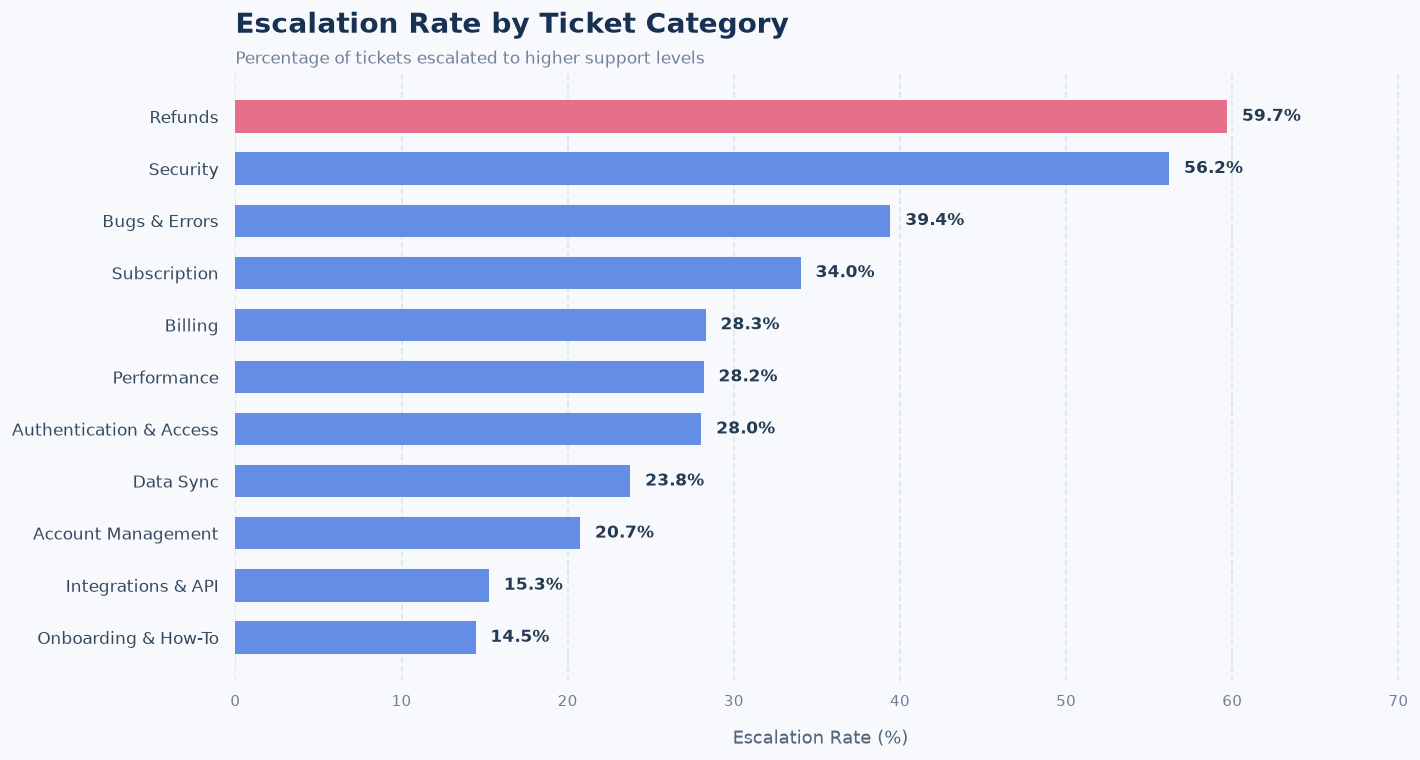

In [19]:

# 4.1 — Escalation Rate by Ticket Category | Modern Style

import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Calculate escalation rate
escalation_data = df[["category", "escalated"]].dropna()
escalation_data = escalation_data[
    escalation_data["escalated"].isin(["Yes", "No"])
]

escalation_by_category = (
    escalation_data.groupby("category")
    .agg(
        Total_Tickets=("escalated", "size"),
        Escalated_Tickets=("escalated", lambda x: x.eq("Yes").sum())
    )
    .reset_index()
)

escalation_by_category["Escalation_Rate_%"] = (
    escalation_by_category["Escalated_Tickets"]
    / escalation_by_category["Total_Tickets"] * 100
)

escalation_by_category = escalation_by_category.sort_values(
    "Escalation_Rate_%", ascending=True
)

# Modern styling
sns.set_theme(style="white", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(12, 6.5), dpi=120)
fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

# Highlight the highest category
rates = escalation_by_category["Escalation_Rate_%"].to_numpy()
colors = [
    "#E76F8A" if rate == rates.max() else "#648DE5"
    for rate in rates
]

bars = ax.barh(
    escalation_by_category["category"],
    rates,
    color=colors,
    height=0.62,
    edgecolor="none",
    zorder=3
)

# Value labels
for bar, rate in zip(bars, rates):
    ax.text(
        bar.get_width() + max(rates.max() * 0.015, 0.05),
        bar.get_y() + bar.get_height() / 2,
        f"{rate:.1f}%",
        va="center",
        ha="left",
        fontsize=10,
        fontweight="bold",
        color="#243B53"
    )

# Titles
ax.set_title(
    "Escalation Rate by Ticket Category",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#183153",
    pad=24
)

ax.text(
    0, 1.015,
    "Percentage of tickets escalated to higher support levels",
    transform=ax.transAxes,
    fontsize=10,
    color="#718096"
)

# Clean axes
ax.set_xlabel("Escalation Rate (%)", fontsize=11, color="#526579", labelpad=12)
ax.set_ylabel("")
ax.set_xlim(0, max(rates.max() * 1.18, 1))
ax.xaxis.grid(True, linestyle="--", alpha=0.25, color="#8FA3BF", zorder=0)
ax.set_axisbelow(True)

ax.tick_params(axis="y", labelsize=10, colors="#34495E", length=0, pad=10)
ax.tick_params(axis="x", labelsize=9, colors="#718096", length=0, pad=8)

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


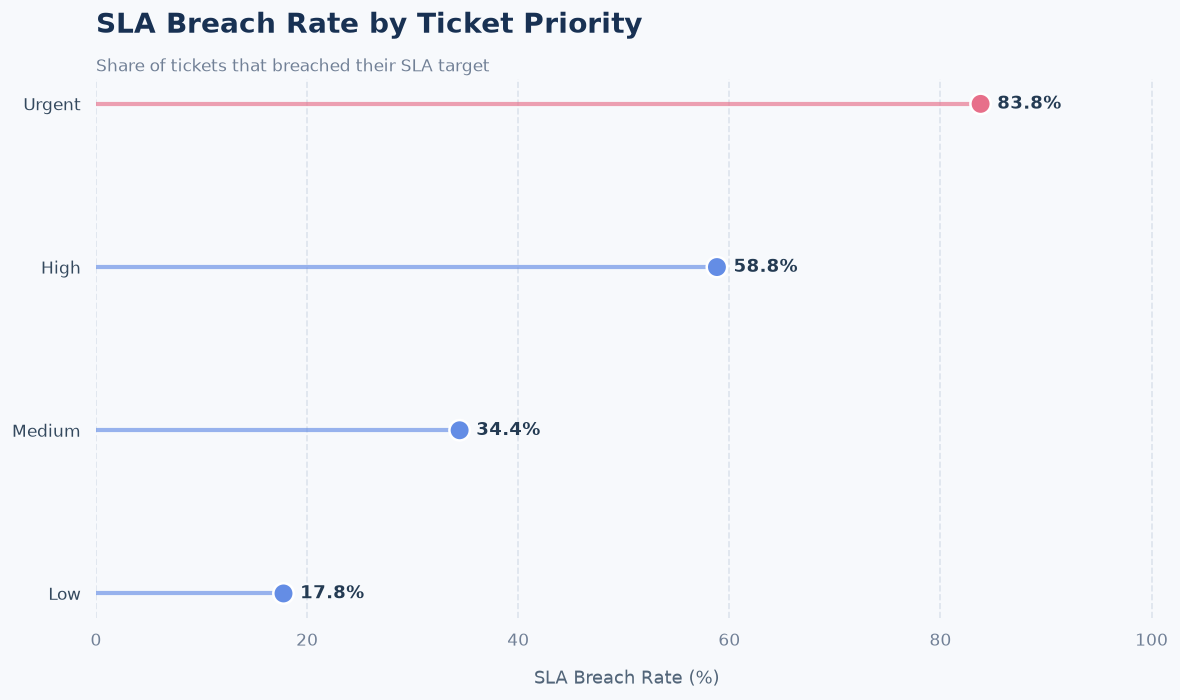

In [21]:

# 4.2 — SLA Breach Rate by Priority | Lollipop Chart

# Calculate SLA breach rate using valid records only
sla_by_priority = (
    df[df["sla_breached"].isin(["Yes", "No"])]
    .groupby("priority")
    .agg(
        Total_Tickets=("sla_breached", "size"),
        SLA_Breaches=("sla_breached", lambda x: x.eq("Yes").sum())
    )
    .reset_index()
)

sla_by_priority["SLA_Breach_Rate_%"] = (
    sla_by_priority["SLA_Breaches"]
    / sla_by_priority["Total_Tickets"] * 100
)

# Sort priorities by breach rate
plot_data = sla_by_priority.sort_values(
    "SLA_Breach_Rate_%", ascending=True
).copy()

sns.set_theme(style="white", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(10, 6), dpi=120)

fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

rates = plot_data["SLA_Breach_Rate_%"].to_numpy()
priorities = plot_data["priority"].astype(str).to_numpy()

# Highlight the highest breach rate
colors = [
    "#E76F8A" if rate == rates.max() else "#648DE5"
    for rate in rates
]

# Lines from zero to each value
for priority, rate, color in zip(priorities, rates, colors):
    ax.hlines(
        y=priority,
        xmin=0,
        xmax=rate,
        color=color,
        linewidth=2.5,
        alpha=0.65,
        zorder=2
    )

# Circular markers
ax.scatter(
    rates,
    priorities,
    s=150,
    c=colors,
    edgecolors="white",
    linewidths=1.5,
    zorder=3
)

# Value labels
for priority, rate in zip(priorities, rates):
    ax.annotate(
        f"{rate:.1f}%",
        xy=(rate, priority),
        xytext=(10, 0),
        textcoords="offset points",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="#243B53"
    )

# Titles
ax.set_title(
    "SLA Breach Rate by Ticket Priority",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#183153",
    pad=28
)

ax.text(
    0, 1.015,
    "Share of tickets that breached their SLA target",
    transform=ax.transAxes,
    fontsize=10,
    color="#718096"
)

# Clean axes
ax.set_xlabel(
    "SLA Breach Rate (%)",
    fontsize=11,
    color="#526579",
    labelpad=12
)
ax.set_ylabel("")

ax.set_xlim(0, max(rates.max() * 1.2, 1))

ax.xaxis.grid(
    True,
    linestyle="--",
    alpha=0.25,
    color="#8FA3BF"
)
ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, pad=9, labelsize=10)
ax.tick_params(axis="y", colors="#34495E")
ax.tick_params(axis="x", colors="#718096")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


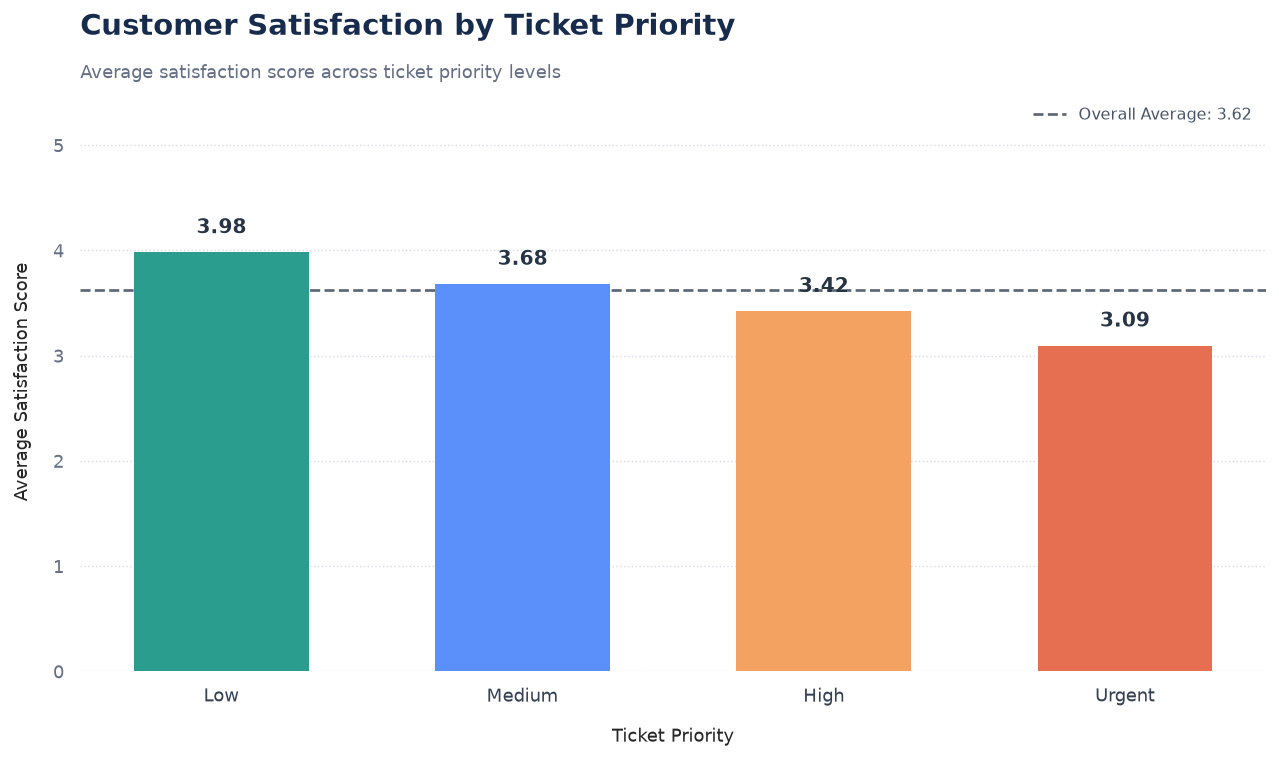

In [22]:

# 4.3 — Average Customer Satisfaction by Priority | Vertical Bar Chart

sns.set_theme(style="white", font="DejaVu Sans")

satisfaction_data = df[
    ["priority", "customer_satisfaction_score"]
].dropna()

priority_order = ["Low", "Medium", "High", "Urgent"]

satisfaction_by_priority = (
    satisfaction_data.groupby("priority")
    .agg(
        Average_Satisfaction=("customer_satisfaction_score", "mean"),
        Response_Count=("customer_satisfaction_score", "count")
    )
    .reindex(priority_order)
    .dropna()
    .reset_index()
)

overall_average = satisfaction_data[
    "customer_satisfaction_score"
].mean()

fig, ax = plt.subplots(figsize=(10, 6), dpi=130)

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

palette = {
    "Low": "#2A9D8F",
    "Medium": "#5B8FF9",
    "High": "#F4A261",
    "Urgent": "#E76F51"
}

bars = ax.bar(
    satisfaction_by_priority["priority"],
    satisfaction_by_priority["Average_Satisfaction"],
    color=[
        palette[p]
        for p in satisfaction_by_priority["priority"]
    ],
    width=0.58,
    edgecolor="none",
    zorder=3
)

# Overall satisfaction reference line
ax.axhline(
    overall_average,
    color="#344054",
    linestyle="--",
    linewidth=1.5,
    alpha=0.8,
    label=f"Overall Average: {overall_average:.2f}",
    zorder=2
)

# Score labels above bars
for bar in bars:
    height = bar.get_height()

    ax.annotate(
        f"{height:.2f}",
        xy=(bar.get_x() + bar.get_width() / 2, height),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold",
        color="#263445"
    )

# Title and subtitle
ax.set_title(
    "Customer Satisfaction by Ticket Priority",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#172B4D",
    pad=32
)

ax.text(
    0,
    1.025,
    "Average satisfaction score across ticket priority levels",
    transform=ax.transAxes,
    fontsize=10,
    color="#667085"
)

ax.set_xlabel("Ticket Priority", fontsize=10, labelpad=12)
ax.set_ylabel("Average Satisfaction Score", fontsize=10, labelpad=12)

ax.set_ylim(0, 5.5)
ax.set_yticks(np.arange(0, 5.1, 1))

ax.yaxis.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    color="#D0D5DD",
    alpha=0.8
)

ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, labelsize=10, pad=9)
ax.tick_params(axis="x", colors="#344054")
ax.tick_params(axis="y", colors="#667085")

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(
    loc="upper right",
    frameon=False,
    fontsize=9,
    labelcolor="#475467"
)

plt.tight_layout()
plt.show()


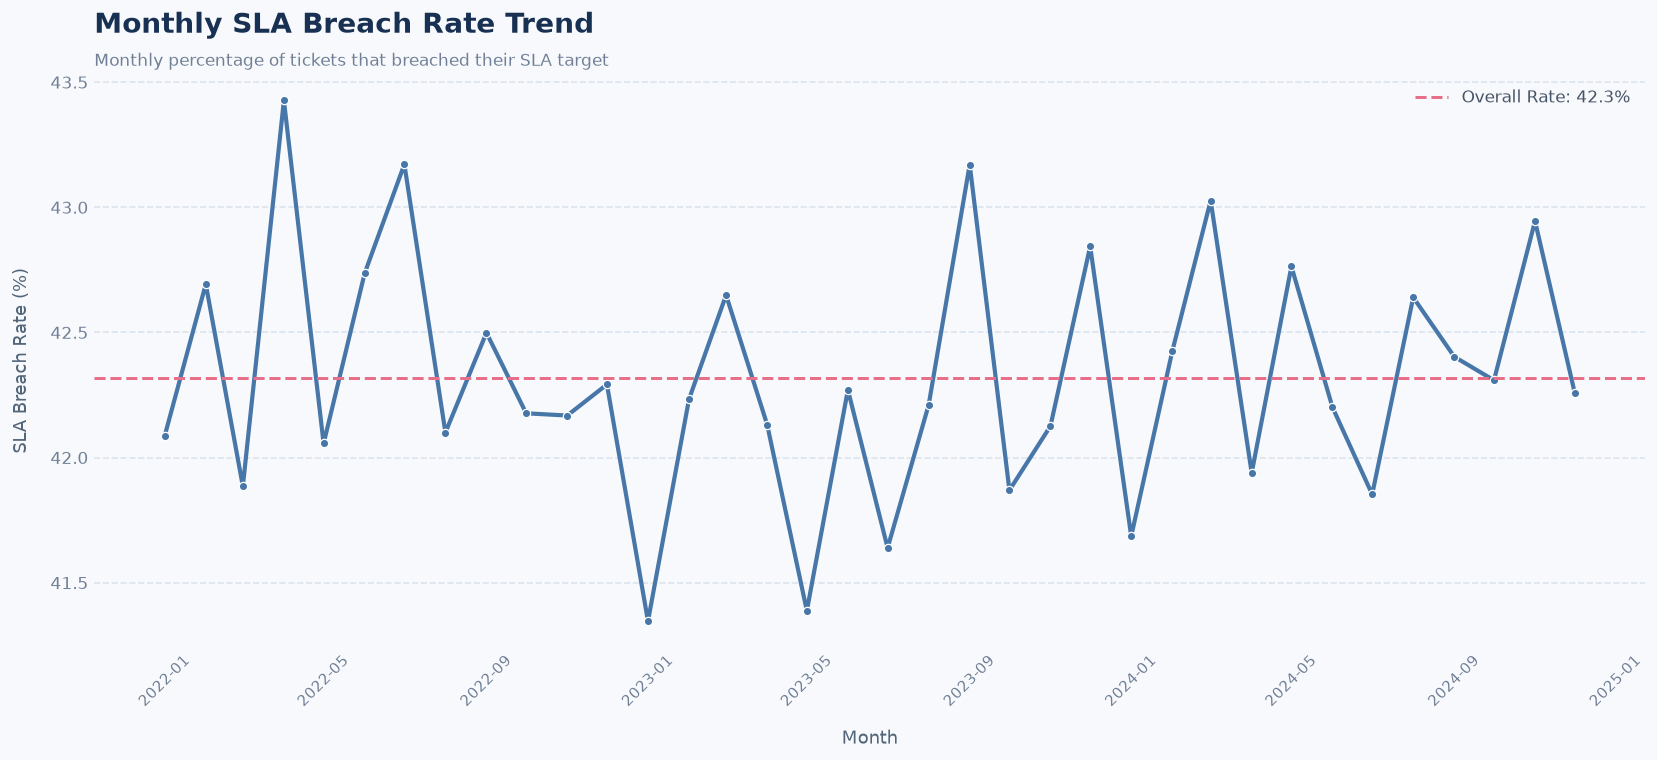

In [23]:

# 4.4 — Monthly SLA Breach Trend | Modern Line Chart

monthly_df = df[["created_at", "sla_breached"]].dropna().copy()

monthly_df = monthly_df[
    monthly_df["sla_breached"].isin(["Yes", "No"])
]

monthly_df["month"] = (
    pd.to_datetime(monthly_df["created_at"])
    .dt.to_period("M")
    .dt.to_timestamp()
)

monthly_sla = (
    monthly_df.groupby("month")
    .agg(
        Total_Tickets=("sla_breached", "size"),
        SLA_Breaches=("sla_breached", lambda x: x.eq("Yes").sum())
    )
    .reset_index()
)

monthly_sla["SLA_Breach_Rate_%"] = (
    monthly_sla["SLA_Breaches"]
    / monthly_sla["Total_Tickets"] * 100
)

# Overall breach rate across all valid records
overall_sla_rate = (
    monthly_sla["SLA_Breaches"].sum()
    / monthly_sla["Total_Tickets"].sum() * 100
)

sns.set_theme(style="white", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(14, 6.5), dpi=120)

fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

sns.lineplot(
    data=monthly_sla,
    x="month",
    y="SLA_Breach_Rate_%",
    marker="o",
    markersize=5,
    linewidth=2.5,
    color="#4776A8",
    ax=ax
)

# Overall reference line
ax.axhline(
    overall_sla_rate,
    color="#E76F8A",
    linestyle="--",
    linewidth=1.8,
    label=f"Overall Rate: {overall_sla_rate:.1f}%"
)

ax.set_title(
    "Monthly SLA Breach Rate Trend",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#183153",
    pad=25
)

ax.text(
    0, 1.015,
    "Monthly percentage of tickets that breached their SLA target",
    transform=ax.transAxes,
    fontsize=10,
    color="#718096"
)

ax.set_xlabel("Month", fontsize=11, color="#526579", labelpad=12)
ax.set_ylabel("SLA Breach Rate (%)", fontsize=11, color="#526579", labelpad=12)

ax.xaxis.grid(False)
ax.yaxis.grid(
    True,
    linestyle="--",
    alpha=0.25,
    color="#8FA3BF"
)

ax.set_axisbelow(True)
ax.tick_params(axis="x", rotation=45, labelsize=9, colors="#718096", length=0)
ax.tick_params(axis="y", labelsize=10, colors="#718096", length=0)

for spine in ax.spines.values():
    spine.set_visible(False)

ax.legend(frameon=False, fontsize=10, labelcolor="#475467")

plt.tight_layout()
plt.show()


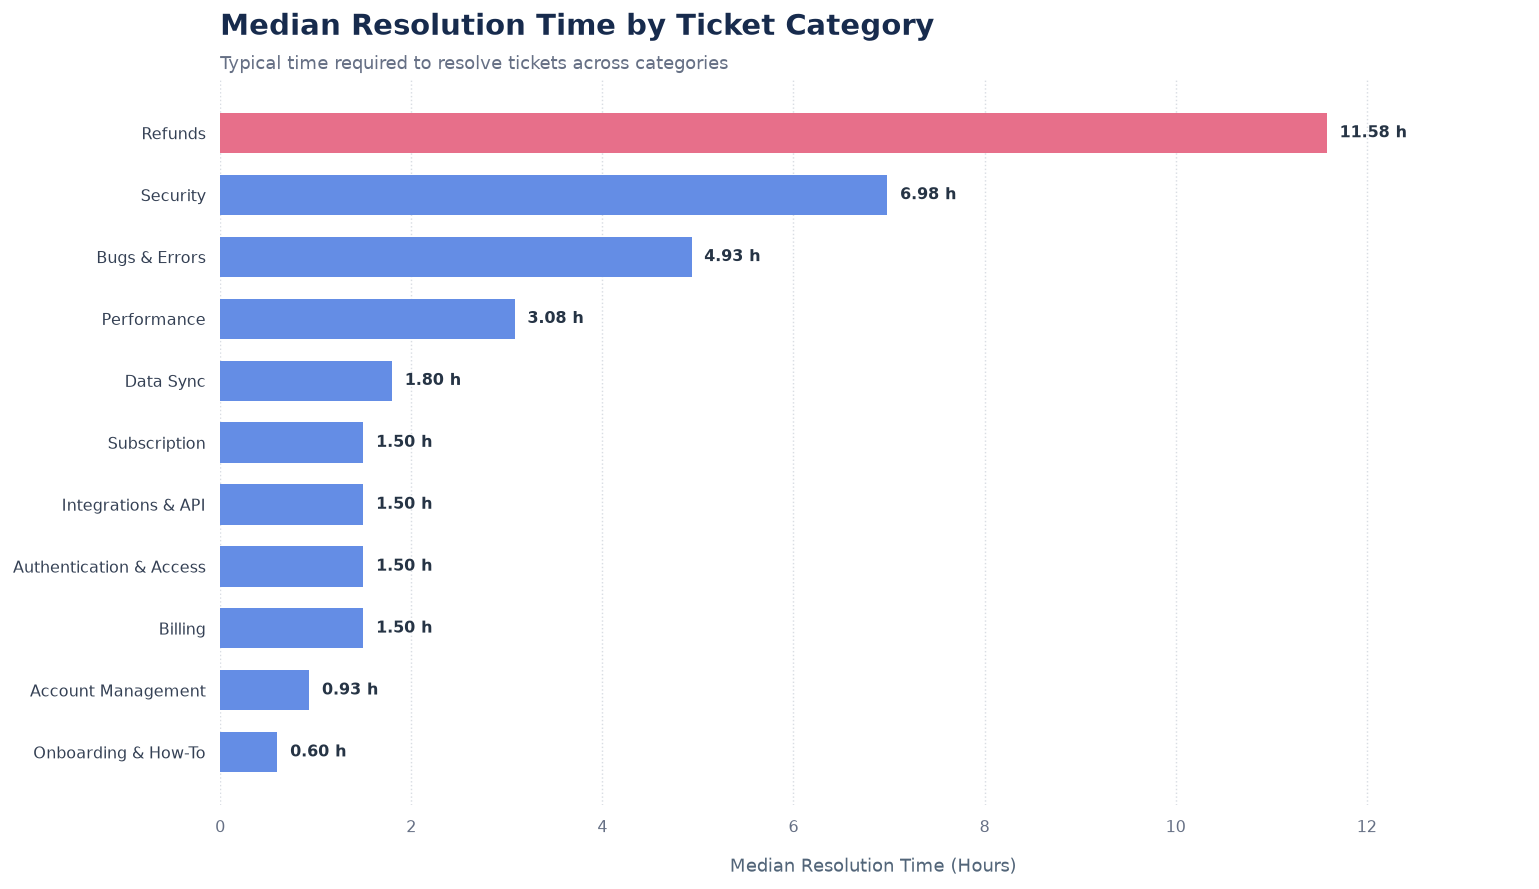

In [24]:

# 4.5 — Median Resolution Time by Ticket Category | Horizontal Bar Chart

resolution_by_category = (
    df.groupby("category", observed=True)
    .agg(
        Median_Resolution_Hours=("resolution_time_hours", "median"),
        Ticket_Count=("resolution_time_hours", "count")
    )
    .reset_index()
    .dropna(subset=["Median_Resolution_Hours"])
    .sort_values("Median_Resolution_Hours", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7), dpi=130)

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Highlight the category with the longest median resolution time
max_category = resolution_by_category[
    "Median_Resolution_Hours"
].idxmax()

colors = [
    "#E76F8A" if idx == max_category else "#648DE5"
    for idx in resolution_by_category.index
]

bars = ax.barh(
    resolution_by_category["category"].astype(str),
    resolution_by_category["Median_Resolution_Hours"],
    color=colors,
    height=0.65,
    edgecolor="none",
    zorder=3
)

# Median values at the end of each bar
for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"{width:.2f} h",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#263445"
    )

ax.set_title(
    "Median Resolution Time by Ticket Category",
    loc="left",
    fontsize=16,
    fontweight="bold",
    color="#172B4D",
    pad=25
)

ax.text(
    0,
    1.015,
    "Typical time required to resolve tickets across categories",
    transform=ax.transAxes,
    fontsize=10,
    color="#667085"
)

ax.set_xlabel(
    "Median Resolution Time (Hours)",
    fontsize=10,
    labelpad=12,
    color="#526579"
)
ax.set_ylabel("")

ax.set_xlim(
    0,
    resolution_by_category["Median_Resolution_Hours"].max() * 1.18
)

ax.xaxis.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    color="#D0D5DD",
    alpha=0.8
)

ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, labelsize=9, pad=8)
ax.tick_params(axis="y", colors="#344054")
ax.tick_params(axis="x", colors="#667085")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


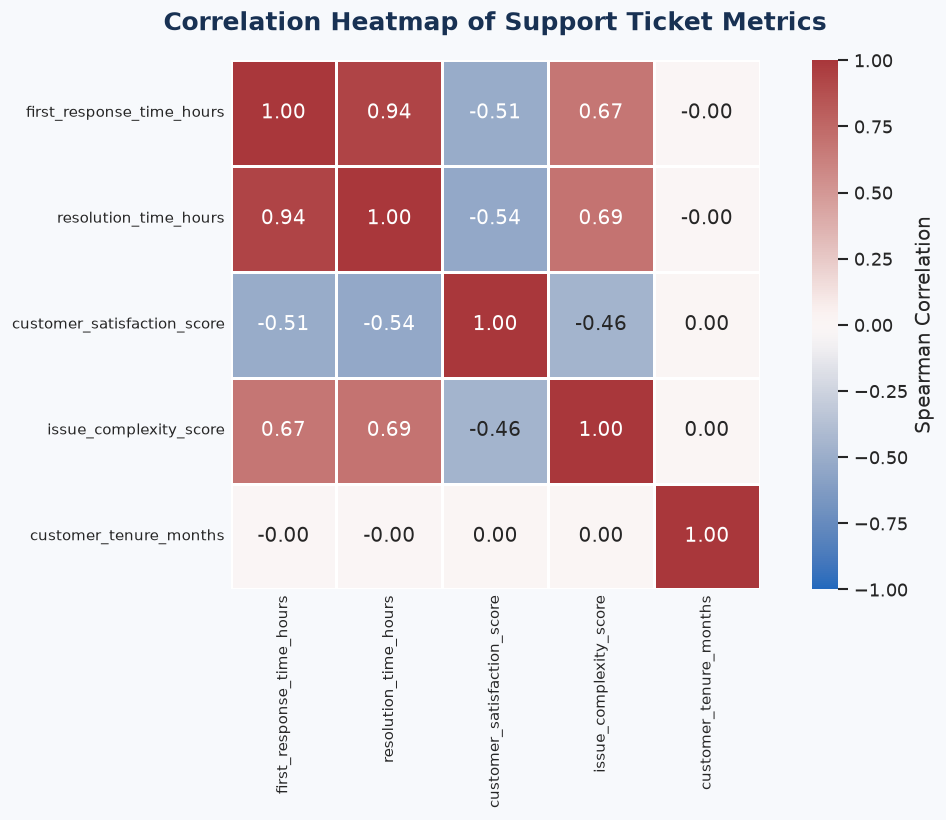

In [25]:

# 4.6 — Correlation Heatmap

correlation_columns = [
    "first_response_time_hours",
    "resolution_time_hours",
    "customer_satisfaction_score",
    "issue_complexity_score",
    "customer_tenure_months"
]

correlation_data = df[correlation_columns].copy()

correlation_matrix = correlation_data.corr(method="spearman")

sns.set_theme(style="white", font="DejaVu Sans")

fig, ax = plt.subplots(figsize=(10, 7), dpi=120)

fig.patch.set_facecolor("#F7F9FC")
ax.set_facecolor("#F7F9FC")

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.7,
    linecolor="white",
    square=True,
    cbar_kws={"label": "Spearman Correlation"},
    ax=ax
)

ax.set_title(
    "Correlation Heatmap of Support Ticket Metrics",
    fontsize=15,
    fontweight="bold",
    color="#183153",
    pad=18
)

ax.tick_params(axis="both", labelsize=9, length=0)

plt.tight_layout()
plt.show()


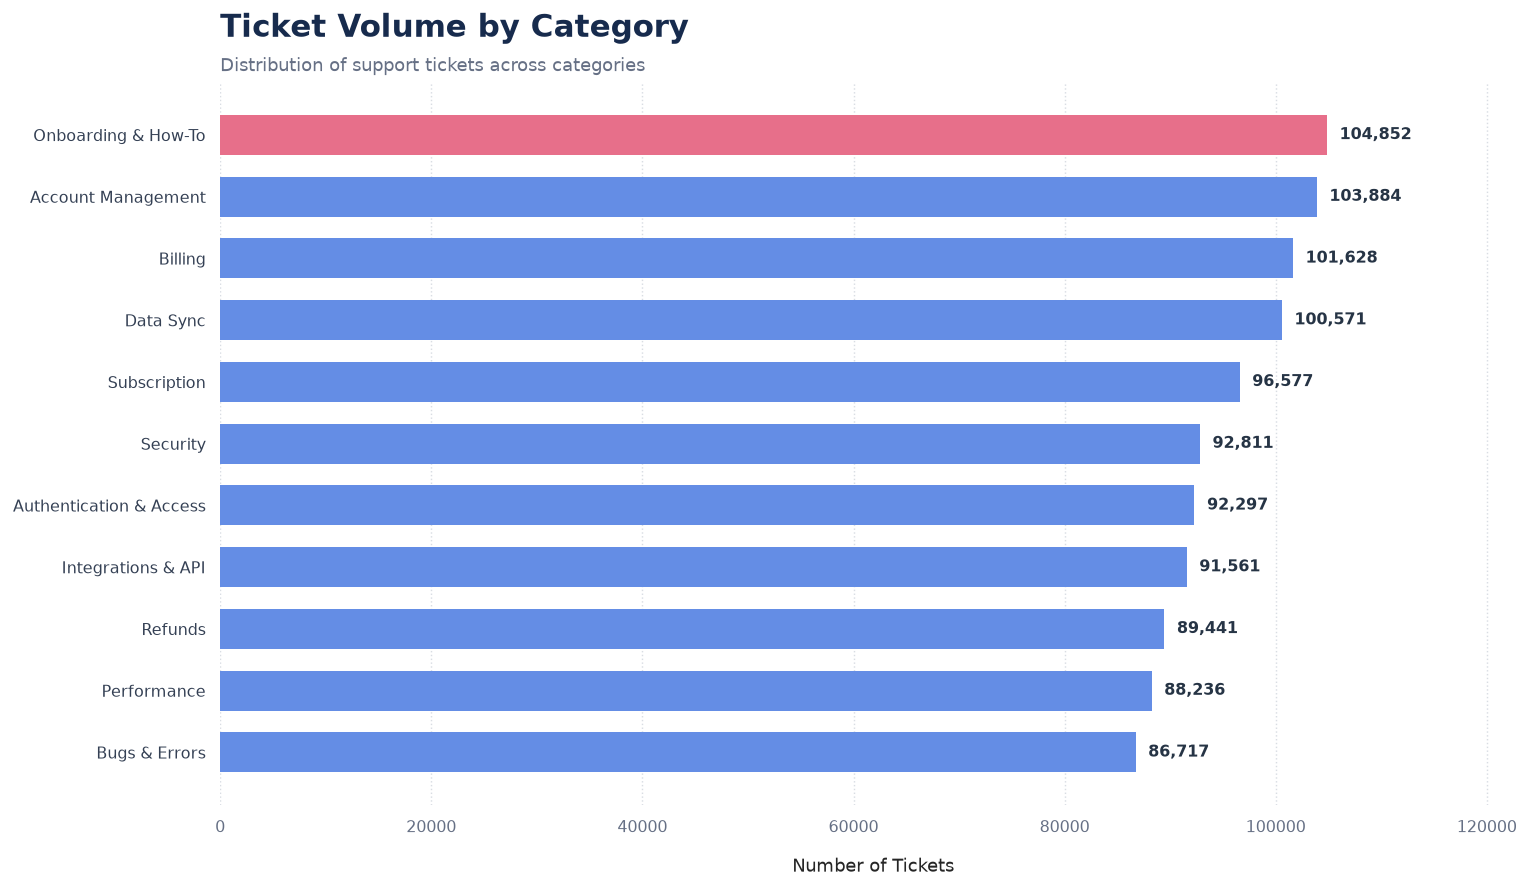

In [26]:

# 4.7 — Ticket Volume by Category | Horizontal Bar Chart

ticket_volume = (
    df.groupby("category", observed=True)
    .size()
    .reset_index(name="Ticket_Count")
    .sort_values("Ticket_Count", ascending=True)
)

fig, ax = plt.subplots(figsize=(12, 7), dpi=130)

fig.patch.set_facecolor("#FFFFFF")
ax.set_facecolor("#FFFFFF")

# Highlight the category with the highest ticket volume
max_count = ticket_volume["Ticket_Count"].max()

colors = [
    "#E76F8A" if count == max_count else "#648DE5"
    for count in ticket_volume["Ticket_Count"]
]

bars = ax.barh(
    ticket_volume["category"].astype(str),
    ticket_volume["Ticket_Count"],
    color=colors,
    height=0.65,
    edgecolor="none",
    zorder=3
)

# Add ticket counts at the end of the bars
for bar in bars:
    width = bar.get_width()

    ax.annotate(
        f"{width:,.0f}",
        xy=(width, bar.get_y() + bar.get_height() / 2),
        xytext=(7, 0),
        textcoords="offset points",
        ha="left",
        va="center",
        fontsize=9,
        fontweight="bold",
        color="#263445"
    )

ax.set_title(
    "Ticket Volume by Category",
    loc="left",
    fontsize=17,
    fontweight="bold",
    color="#172B4D",
    pad=25
)

ax.text(
    0,
    1.015,
    "Distribution of support tickets across categories",
    transform=ax.transAxes,
    fontsize=10,
    color="#667085"
)

ax.set_xlabel("Number of Tickets", fontsize=10, labelpad=12)
ax.set_ylabel("")

ax.set_xlim(0, max_count * 1.18)

ax.xaxis.grid(
    True,
    linestyle=":",
    linewidth=0.8,
    color="#D0D5DD",
    alpha=0.8
)

ax.set_axisbelow(True)

ax.tick_params(axis="both", length=0, labelsize=9, pad=8)
ax.tick_params(axis="y", colors="#344054")
ax.tick_params(axis="x", colors="#667085")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.tight_layout()
plt.show()


05 — MACHINE LEARNING

In [27]:

# 5.1 — Target Analysis & Data Quality

target_col = "sla_breach_margin_minutes"

print("Dataset shape:", df.shape)
print("Target:", target_col)

# Target availability
target_missing = df[target_col].isna().sum()
target_available = df[target_col].notna().sum()

print(f"\nAvailable target values: {target_available:,}")
print(f"Missing target values: {target_missing:,}")
print(f"Missing target percentage: {df[target_col].isna().mean() * 100:.2f}%")

# Target distribution
print("\nTarget descriptive statistics:")
display(df[target_col].describe().to_frame().round(2))

# Positive, negative, and zero values
target_values = df[target_col].dropna()

target_summary = pd.DataFrame({
    "Count": [
        target_values.lt(0).sum(),
        target_values.gt(0).sum(),
        target_values.eq(0).sum()
    ]
}, index=[
    "Negative — SLA time exceeded",
    "Positive — Within SLA time",
    "Zero — Exactly at SLA boundary"
])

target_summary["Percentage_%"] = (
    target_summary["Count"] / len(target_values) * 100
).round(2)

print("\nTarget sign distribution:")
display(target_summary)

# Missing target by ticket status
print("\nTarget availability by ticket status:")

target_by_status = (
    df.assign(Target_Missing=df[target_col].isna())
    .groupby("status", dropna=False)
    .agg(
        Total_Tickets=("TicketKey", "size"),
        Missing_Target=("Target_Missing", "sum")
    )
)

target_by_status["Missing_Target_%"] = (
    target_by_status["Missing_Target"]
    / target_by_status["Total_Tickets"] * 100
).round(2)

display(target_by_status.sort_values(
    "Missing_Target_%", ascending=False
))


Dataset shape: (1048575, 27)
Target: sla_breach_margin_minutes

Available target values: 941,604
Missing target values: 106,971
Missing target percentage: 10.20%

Target descriptive statistics:


,sla_breach_margin_minutes
count,941604.00
mean,-1691.27
std,9645.09
min,-107858.00
25%,-3220.00
50%,693.00
75%,4024.00
max,7197.00



Target sign distribution:


,Count,Percentage_%
Negative — SLA time exceeded,398430,42.31
Positive — Within SLA time,543076,57.68
Zero — Exactly at SLA boundary,98,0.01



Target availability by ticket status:


,Total_Tickets,Missing_Target,Missing_Target_%
status,,,
Cancelled,39308,39308,100.0
New,516,516,100.0
On-Hold,7528,7528,100.0
Pending,11261,11261,100.0
Open,48358,48358,100.0
Closed,937144,0,0.0
Resolved,4460,0,0.0


In [28]:

# 5.2 — Feature Availability & Leakage Review

target_col = "sla_breach_margin_minutes"

candidate_features = [
    "priority",
    "category",
    "issue_type",
    "customer_age",
    "customer_gender",
    "customer_tenure_months",
    "customer_segment",
    "subscription_type",
    "product",
    "channel",
    "region",
    "language",
    "escalated",
    "sla_target_hours",
    "first_response_time_hours",
    "paused_hours",
    "reopen_count",
    "issue_complexity_score"
]

leakage_or_exclusion = [
    "sla_breached",
    "resolution_time_hours",
    "resolution_wallclock_hours",
    "status",
    "sla_breach_margin_minutes",
    "TicketKey",
    "TicketId",
    "created_at"
]

feature_review = pd.DataFrame({
    "Feature": candidate_features + leakage_or_exclusion,
    "Role": (
        ["Candidate"] * len(candidate_features)
        + ["Exclude initially"] * len(leakage_or_exclusion)
    )
})

feature_review["Exists_in_df"] = feature_review["Feature"].isin(df.columns)

feature_review["Missing_%"] = feature_review["Feature"].map(
    df.isna().mean().mul(100)
).round(2)

display(feature_review)


,Feature,Role,Exists_in_df,Missing_%
0,priority,Candidate,True,0.00
1,category,Candidate,True,0.00
2,issue_type,Candidate,True,0.00
3,customer_age,Candidate,True,0.00
4,customer_gender,Candidate,True,0.00
5,customer_tenure_months,Candidate,True,0.00
6,customer_segment,Candidate,True,0.00
7,subscription_type,Candidate,True,0.00
8,product,Candidate,True,0.00
9,channel,Candidate,True,0.00


In [29]:
# 5.3 — Prepare Modeling Dataset

target_col = "sla_breach_margin_minutes"

features = [
    "priority",
    "category",
    "issue_type",
    "customer_age",
    "customer_gender",
    "customer_tenure_months",
    "customer_segment",
    "subscription_type",
    "product",
    "channel",
    "region",
    "language",
    "sla_target_hours",
    "issue_complexity_score"
]

# Keep only rows with an available target
model_df = df[features + [target_col]].dropna(
    subset=[target_col]
).copy()

X = model_df[features]
y = model_df[target_col]

print("Modeling dataset shape:", model_df.shape)
print("Number of features:", len(features))
print(f"Available target records: {len(y):,}")
print(f"Missing target records excluded: {df[target_col].isna().sum():,}")

print("\nTarget summary:")
display(y.describe().to_frame().round(2))

print("\nFeature types:")
display(X.dtypes.astype(str).to_frame("Data Type"))

print("\nRemaining missing values:")
display(
    model_df.isna().sum()
    .loc[lambda s: s > 0]
    .to_frame("Missing Values")
)

Modeling dataset shape: (941604, 15)
Number of features: 14
Available target records: 941,604
Missing target records excluded: 106,971

Target summary:


,sla_breach_margin_minutes
count,941604.00
mean,-1691.27
std,9645.09
min,-107858.00
25%,-3220.00
50%,693.00
75%,4024.00
max,7197.00



Feature types:


,Data Type
priority,str
category,str
issue_type,str
customer_age,int64
customer_gender,str
customer_tenure_months,int64
customer_segment,str
subscription_type,str
product,str
channel,str



Remaining missing values:


,Missing Values


In [30]:

# 5.4 — Target Outlier Investigation

target_col = "sla_breach_margin_minutes"
target_values = df[target_col].dropna()

Q1 = target_values.quantile(0.25)
Q3 = target_values.quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = target_values[
    (target_values < lower_bound) |
    (target_values > upper_bound)
]

print("IQR Outlier Analysis")
print("-" * 40)
print(f"Q1: {Q1:,.2f}")
print(f"Q3: {Q3:,.2f}")
print(f"IQR: {IQR:,.2f}")
print(f"Lower bound: {lower_bound:,.2f}")
print(f"Upper bound: {upper_bound:,.2f}")
print(f"Outlier count: {len(outliers):,}")
print(f"Outlier percentage: {len(outliers) / len(target_values) * 100:.2f}%")

print("\nExtreme negative target quantiles:")
display(
    target_values.quantile(
        [0, 0.001, 0.01, 0.05, 0.10, 0.25, 0.50, 0.75, 0.95, 0.99, 0.999, 1]
    ).to_frame("Target Minutes").round(2)
)

print("\n10 most negative target values:")
display(
    target_values.nsmallest(10).to_frame("sla_breach_margin_minutes")
)


IQR Outlier Analysis
----------------------------------------
Q1: -3,220.00
Q3: 4,024.00
IQR: 7,244.00
Lower bound: -14,086.00
Upper bound: 14,890.00
Outlier count: 86,106
Outlier percentage: 9.14%

Extreme negative target quantiles:


,Target Minutes
0.000,-107858.00
0.001,-61706.79
0.010,-43024.00
0.050,-19628.00
0.100,-12960.00
0.250,-3220.00
0.500,693.00
0.750,4024.00
0.950,7105.00
0.990,7181.00



10 most negative target values:


,sla_breach_margin_minutes
918576,-107858.0
286821,-103622.0
814428,-103030.0
326392,-97828.0
458383,-95114.0
697585,-92273.0
1045709,-89533.0
268485,-89278.0
462543,-89144.0
123598,-88965.0


In [31]:

# 5.5 — Investigate Extreme Target Values

target_col = "sla_breach_margin_minutes"

investigation_df = df.loc[
    df[target_col].notna(),
    [
        "TicketId",
        "sla_breach_margin_minutes",
        "sla_target_hours",
        "resolution_time_hours",
        "resolution_wallclock_hours",
        "paused_hours",
        "first_response_time_hours",
        "status"
    ]
].copy()

investigation_df["Target_Outlier"] = (
    investigation_df[target_col] < lower_bound
)

print("Target vs resolution time correlation:")
display(
    investigation_df[
        [
            "sla_breach_margin_minutes",
            "resolution_time_hours",
            "resolution_wallclock_hours",
            "paused_hours",
            "first_response_time_hours"
        ]
    ].corr(method="spearman").round(3)
)

print("\nExtreme negative target records:")
display(
    investigation_df.nsmallest(
        10, target_col
    ).round(2)
)

print("\nTarget outlier rate by resolution-time group:")

investigation_df["Resolution_Group"] = pd.cut(
    investigation_df["resolution_time_hours"],
    bins=[-float("inf"), 1, 4, 24, 72, 168, float("inf")],
    labels=[
        "<= 1 hour",
        "1–4 hours",
        "4–24 hours",
        "1–3 days",
        "3–7 days",
        "> 7 days"
    ]
)

outlier_summary = (
    investigation_df.groupby(
        "Resolution_Group", observed=False
    )
    .agg(
        Ticket_Count=(target_col, "size"),
        Median_Target=(target_col, "median"),
        Outlier_Count=("Target_Outlier", "sum")
    )
)

outlier_summary["Outlier_Rate_%"] = (
    outlier_summary["Outlier_Count"]
    / outlier_summary["Ticket_Count"] * 100
).round(2)

display(outlier_summary.round(2))


Target vs resolution time correlation:


,sla_breach_margin_minutes,resolution_time_hours,resolution_wallclock_hours,paused_hours,first_response_time_hours
sla_breach_margin_minutes,1.000,-0.566,-0.807,-0.189,-0.551
resolution_time_hours,-0.566,1.000,0.590,-0.001,0.937
resolution_wallclock_hours,-0.807,0.590,1.000,0.309,0.579
paused_hours,-0.189,-0.001,0.309,1.000,-0.001
first_response_time_hours,-0.551,0.937,0.579,-0.001,1.000



Extreme negative target records:


,TicketId,sla_breach_margin_minutes,sla_target_hours,resolution_time_hours,resolution_wallclock_hours,paused_hours,first_response_time_hours,status,Target_Outlier
918576,918577,-107858.0,72,192.00,1869.63,414.40,53.85,Closed,True
286821,286822,-103622.0,120,192.00,1847.03,367.05,61.10,Closed,True
814428,814429,-103030.0,24,52.87,1741.17,877.25,6.67,Closed,True
326392,326393,-97828.0,24,192.00,1654.47,362.83,43.78,Closed,True
458383,458384,-95114.0,72,3.08,1657.23,1005.42,0.92,Closed,True
697585,697586,-92273.0,72,183.48,1609.88,419.37,27.62,Closed,True
1045709,1045710,-89533.0,24,192.00,1516.22,0.00,70.60,Closed,True
268485,268486,-89278.0,24,162.12,1511.97,103.22,22.48,Closed,True
462543,462544,-89144.0,24,192.00,1509.73,34.68,66.87,Closed,True
123598,123599,-88965.0,72,192.00,1554.75,131.42,76.93,Closed,True



Target outlier rate by resolution-time group:


,Ticket_Count,Median_Target,Outlier_Count,Outlier_Rate_%
Resolution_Group,,,,
<= 1 hour,277298,3988.0,8353,3.01
1–4 hours,292888,1135.0,22898,7.82
4–24 hours,239136,-278.0,13123,5.49
1–3 days,86769,-7385.0,12778,14.73
3–7 days,42712,-15635.0,27804,65.10
> 7 days,2801,-8739.0,1150,41.06


In [32]:

# 5.6 — Split Data and Build Preprocessing Pipeline

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

categorical_features = X.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X.select_dtypes(
    include=["number"]
).columns.tolist()

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Training records:", f"{len(X_train):,}")
print("Testing records:", f"{len(X_test):,}")
print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Missing values in training features:", X_train.isna().sum().sum())
print("Missing values in test features:", X_test.isna().sum().sum())


Training records: 753,283
Testing records: 188,321
Numerical features: 4
Categorical features: 10
Missing values in training features: 0
Missing values in test features: 0


In [33]:

# 5.7 — Linear Regression Baseline

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

linear_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

y_pred_lr = linear_model.predict(X_test)

lr_results = {
    "Model": "Linear Regression",
    "MAE": mean_absolute_error(y_test, y_pred_lr),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_lr)),
    "R2": r2_score(y_test, y_pred_lr)
}

display(pd.DataFrame([lr_results]).round(4))


,Model,MAE,RMSE,R2
0,Linear Regression,4972.6531,8528.0033,0.2177


In [34]:

# 5.8 — Random Forest Regressor

from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    ))
])

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

rf_results = {
    "Model": "Random Forest",
    "MAE": mean_absolute_error(y_test, y_pred_rf),
    "RMSE": np.sqrt(mean_squared_error(y_test, y_pred_rf)),
    "R2": r2_score(y_test, y_pred_rf)
}

results_df = pd.DataFrame([
    lr_results,
    rf_results
]).set_index("Model")

display(results_df.round(4))


,MAE,RMSE,R2
Model,,,
Linear Regression,4972.6531,8528.0033,0.2177
Random Forest,4933.9537,8500.1068,0.2229


In [35]:

# 5.9 — Classification Target Check

target_cls = "sla_breached"

print("Target distribution:")
display(
    df[target_cls]
    .value_counts(dropna=False)
    .rename_axis("SLA Breached")
    .to_frame("Count")
)

print("\nTarget distribution (%):")
display(
    (
        df[target_cls]
        .value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
        .rename_axis("SLA Breached")
        .to_frame("Percentage")
    )
)

print("\nMissing target values:", df[target_cls].isna().sum())

print("\nTarget values:", df[target_cls].dropna().unique())


Target distribution:


,Count
SLA Breached,
No,543076
Yes,398430
NaN,107069



Target distribution (%):


,Percentage
SLA Breached,
No,51.79
Yes,38.00
NaN,10.21



Missing target values: 107069

Target values: <StringArray>
['No', 'Yes']
Length: 2, dtype: str


In [36]:

# 5.10 — Prepare Classification Dataset

from sklearn.model_selection import train_test_split

target_cls = "sla_breached"

classification_features = [
    "priority",
    "category",
    "issue_type",
    "customer_age",
    "customer_gender",
    "customer_tenure_months",
    "customer_segment",
    "subscription_type",
    "product",
    "channel",
    "region",
    "language",
    "sla_target_hours",
    "issue_complexity_score"
]

classification_df = df.loc[
    df[target_cls].notna(),
    classification_features + [target_cls]
].copy()

X_cls = classification_df[classification_features]
y_cls = classification_df[target_cls].map({"No": 0, "Yes": 1})

X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls,
    y_cls,
    test_size=0.20,
    random_state=42,
    stratify=y_cls
)

print("Dataset shape:", classification_df.shape)
print("Training set:", f"{len(X_train_cls):,}")
print("Testing set:", f"{len(X_test_cls):,}")

print("\nTraining target distribution (%):")
display((y_train_cls.value_counts(normalize=True) * 100).round(2))

print("\nTesting target distribution (%):")
display((y_test_cls.value_counts(normalize=True) * 100).round(2))

print("\nMissing values in features:", X_cls.isna().sum().sum())
print("Missing target values after filtering:", y_cls.isna().sum())


Dataset shape: (941506, 15)
Training set: 753,204
Testing set: 188,302

Training target distribution (%):


sla_breached
0    57.68
1    42.32
Name: proportion, dtype: float64


Testing target distribution (%):


sla_breached
0    57.68
1    42.32
Name: proportion, dtype: float64


Missing values in features: 0
Missing target values after filtering: 0


In [37]:

# 5.11 — Logistic Regression Classifier

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train_cls, y_train_cls)

y_pred_log = logistic_model.predict(X_test_cls)
y_prob_log = logistic_model.predict_proba(X_test_cls)[:, 1]

logistic_results = {
    "Model": "Logistic Regression",
    "Accuracy": accuracy_score(y_test_cls, y_pred_log),
    "Precision": precision_score(y_test_cls, y_pred_log),
    "Recall": recall_score(y_test_cls, y_pred_log),
    "F1": f1_score(y_test_cls, y_pred_log),
    "ROC_AUC": roc_auc_score(y_test_cls, y_prob_log),
    "PR_AUC": average_precision_score(y_test_cls, y_prob_log)
}

display(pd.DataFrame([logistic_results]).set_index("Model").round(4))

print("\nClassification Report:")
print(classification_report(
    y_test_cls,
    y_pred_log,
    target_names=["No SLA Breach", "SLA Breach"],
    digits=4
))

print("Confusion Matrix:")
display(pd.DataFrame(
    confusion_matrix(y_test_cls, y_pred_log),
    index=["Actual No", "Actual Yes"],
    columns=["Predicted No", "Predicted Yes"]
))


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7879,0.7541,0.7402,0.7471,0.8599,0.8384



Classification Report:
               precision    recall  f1-score   support

No SLA Breach     0.8119    0.8230    0.8174    108616
   SLA Breach     0.7541    0.7402    0.7471     79686

     accuracy                         0.7879    188302
    macro avg     0.7830    0.7816    0.7822    188302
 weighted avg     0.7875    0.7879    0.7876    188302

Confusion Matrix:


,Predicted No,Predicted Yes
Actual No,89386,19230
Actual Yes,20705,58981


In [38]:

# 5.12 — Random Forest Classifier

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)
import pandas as pd

rf_classifier = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        max_features=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

rf_classifier.fit(X_train_cls, y_train_cls)

y_pred_rf_cls = rf_classifier.predict(X_test_cls)
y_prob_rf_cls = rf_classifier.predict_proba(X_test_cls)[:, 1]

rf_cls_results = {
    "Model": "Random Forest",
    "Accuracy": accuracy_score(y_test_cls, y_pred_rf_cls),
    "Precision": precision_score(y_test_cls, y_pred_rf_cls),
    "Recall": recall_score(y_test_cls, y_pred_rf_cls),
    "F1": f1_score(y_test_cls, y_pred_rf_cls),
    "ROC_AUC": roc_auc_score(y_test_cls, y_prob_rf_cls),
    "PR_AUC": average_precision_score(y_test_cls, y_prob_rf_cls)
}

classification_results = pd.DataFrame([
    logistic_results,
    rf_cls_results
]).set_index("Model")

display(classification_results.round(4))


,Accuracy,Precision,Recall,F1,ROC_AUC,PR_AUC
Model,,,,,,
Logistic Regression,0.7879,0.7541,0.7402,0.7471,0.8599,0.8384
Random Forest,0.7839,0.7415,0.7513,0.7464,0.8572,0.8334


In [39]:

# 5.13 — Feature Importance (Permutation Importance)

from sklearn.inspection import permutation_importance
import pandas as pd

# Use a manageable sample to keep runtime reasonable
sample_size = min(10000, len(X_test_cls))
X_importance = X_test_cls.sample(
    n=sample_size, random_state=42
)
y_importance = y_test_cls.loc[X_importance.index]

importance_result = permutation_importance(
    logistic_model,
    X_importance,
    y_importance,
    scoring="f1",
    n_repeats=3,
    random_state=42,
    n_jobs=-1
)

feature_importance = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std
}).sort_values("Importance_Mean", ascending=False)

display(feature_importance.round(4))


,Feature,Importance_Mean,Importance_Std
2,issue_type,0.1253,0.0004
12,sla_target_hours,0.0662,0.0023
1,category,0.0139,0.0010
0,priority,0.0104,0.0018
13,issue_complexity_score,0.0092,0.0007
10,region,0.0012,0.0011
7,subscription_type,0.0007,0.0002
9,channel,0.0003,0.0001
5,customer_tenure_months,0.0002,0.0002
3,customer_age,-0.0001,0.0001


Final Model: Logistic Regression
               precision    recall  f1-score   support

No SLA Breach     0.8119    0.8230    0.8174    108616
   SLA Breach     0.7541    0.7402    0.7471     79686

     accuracy                         0.7879    188302
    macro avg     0.7830    0.7816    0.7822    188302
 weighted avg     0.7875    0.7879    0.7876    188302



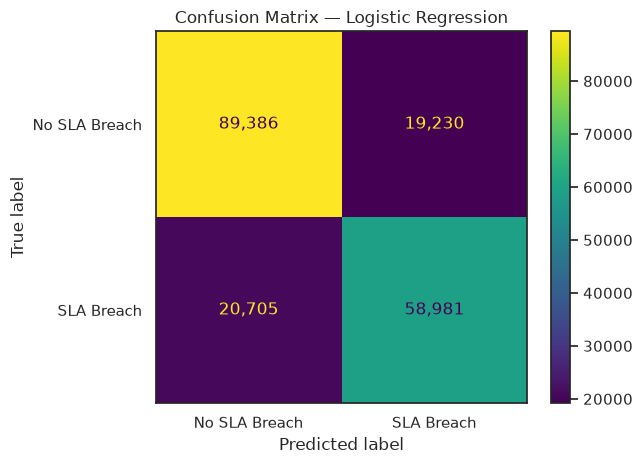

In [40]:

# 5.14 — Final Logistic Regression Evaluation

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

print("Final Model: Logistic Regression")
print("=" * 45)

print(classification_report(
    y_test_cls,
    y_pred_log,
    labels=[0, 1],
    target_names=["No SLA Breach", "SLA Breach"],
    digits=4
))

cm = confusion_matrix(y_test_cls, y_pred_log, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No SLA Breach", "SLA Breach"]
)

disp.plot(values_format=",d")
plt.title("Confusion Matrix — Logistic Regression")
plt.tight_layout()
plt.show()


In [41]:

# 6.1 — Priority Target Distribution

import pandas as pd

print("Priority Distribution:")
display(
    df["priority"]
    .value_counts(dropna=False)
    .rename_axis("Priority")
    .to_frame("Ticket_Count")
)

print("\nPriority Percentage:")
display(
    (df["priority"].value_counts(normalize=True) * 100)
    .round(2)
    .rename_axis("Priority")
    .to_frame("Percentage")
)


Priority Distribution:


,Ticket_Count
Priority,
Medium,350258
Low,291414
High,279106
Urgent,127797



Priority Percentage:


,Percentage
Priority,
Medium,33.40
Low,27.79
High,26.62
Urgent,12.19


In [42]:

# 6.2 — Prepare Priority Classification Dataset

priority_features = [
    "category",
    "issue_type",
    "customer_age",
    "customer_gender",
    "customer_tenure_months",
    "customer_segment",
    "subscription_type",
    "product",
    "channel",
    "region",
    "language",
    "issue_complexity_score"
]

priority_df = df[
    priority_features + ["priority"]
].dropna(subset=["priority"]).copy()

X_priority = priority_df[priority_features]
y_priority = priority_df["priority"]

print("Dataset shape:", priority_df.shape)
print("\nTarget distribution:")
display(y_priority.value_counts())

print("\nMissing values in features:", X_priority.isna().sum().sum())
print("Missing target values:", y_priority.isna().sum())
print("\nNumber of classes:", y_priority.nunique())


Dataset shape: (1048575, 13)

Target distribution:


priority
Medium    350258
Low       291414
High      279106
Urgent    127797
Name: count, dtype: int64


Missing values in features: 0
Missing target values: 0

Number of classes: 4


In [43]:

# 6.3 — Train/Test Split and Preprocessing

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

X_train_priority, X_test_priority, y_train_priority, y_test_priority = (
    train_test_split(
        X_priority,
        y_priority,
        test_size=0.20,
        random_state=42,
        stratify=y_priority
    )
)

categorical_priority = X_priority.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_priority = X_priority.select_dtypes(
    include=["number"]
).columns.tolist()

priority_preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numerical_priority),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_priority)
])

print("Training rows:", len(X_train_priority))
print("Testing rows:", len(X_test_priority))
print("Categorical features:", len(categorical_priority))
print("Numerical features:", len(numerical_priority))

print("\nTraining distribution (%):")
display((y_train_priority.value_counts(normalize=True) * 100).round(2))

print("\nTesting distribution (%):")
display((y_test_priority.value_counts(normalize=True) * 100).round(2))


Training rows: 838860
Testing rows: 209715
Categorical features: 9
Numerical features: 3

Training distribution (%):


priority
Medium    33.40
Low       27.79
High      26.62
Urgent    12.19
Name: proportion, dtype: float64


Testing distribution (%):


priority
Medium    33.40
Low       27.79
High      26.62
Urgent    12.19
Name: proportion, dtype: float64

In [44]:

# 6.4 — Train Priority Classification Model

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

priority_model = Pipeline([
    ("preprocessor", priority_preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

priority_model.fit(X_train_priority, y_train_priority)

y_pred_priority = priority_model.predict(X_test_priority)

print("Priority Classification Results")
print("=" * 40)
print("Accuracy:", round(
    accuracy_score(y_test_priority, y_pred_priority), 4
))
print("Macro Precision:", round(
    precision_score(
        y_test_priority, y_pred_priority,
        average="macro", zero_division=0
    ), 4
))
print("Macro Recall:", round(
    recall_score(
        y_test_priority, y_pred_priority,
        average="macro", zero_division=0
    ), 4
))
print("Macro F1:", round(
    f1_score(
        y_test_priority, y_pred_priority,
        average="macro", zero_division=0
    ), 4
))

print("\nDetailed Classification Report:")
print(classification_report(
    y_test_priority,
    y_pred_priority,
    labels=["Low", "Medium", "High", "Urgent"],
    digits=4,
    zero_division=0
))


Priority Classification Results
Accuracy: 0.4226
Macro Precision: 0.3114
Macro Recall: 0.4474
Macro F1: 0.3555

Detailed Classification Report:
              precision    recall  f1-score   support

         Low     0.5424    0.7097    0.6149     58283
      Medium     0.4528    0.4421    0.4474     70052
        High     0.0000    0.0000    0.0000     55821
      Urgent     0.2505    0.6376    0.3597     25559

    accuracy                         0.4226    209715
   macro avg     0.3114    0.4474    0.3555    209715
weighted avg     0.3325    0.4226    0.3642    209715



In [45]:

# 6.5 — Random Forest for Priority Classification

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score,
    classification_report
)

priority_rf_model = Pipeline([
    ("preprocessor", priority_preprocessor),
    ("model", RandomForestClassifier(
        n_estimators=100,
        max_depth=20,
        min_samples_leaf=5,
        max_features=0.8,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

priority_rf_model.fit(X_train_priority, y_train_priority)

y_pred_priority_rf = priority_rf_model.predict(X_test_priority)

print("Random Forest — Priority Classification")
print("=" * 45)
print("Accuracy:", round(
    accuracy_score(y_test_priority, y_pred_priority_rf), 4
))
print("Macro F1:", round(
    f1_score(
        y_test_priority, y_pred_priority_rf,
        average="macro", zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    y_test_priority,
    y_pred_priority_rf,
    labels=["Low", "Medium", "High", "Urgent"],
    digits=4,
    zero_division=0
))


Random Forest — Priority Classification
Accuracy: 0.4165
Macro F1: 0.3659

Classification Report:
              precision    recall  f1-score   support

         Low     0.5445    0.6849    0.6066     58283
      Medium     0.4319    0.4368    0.4343     70052
        High     0.3993    0.0503    0.0894     55821
      Urgent     0.2395    0.5483    0.3334     25559

    accuracy                         0.4165    209715
   macro avg     0.4038    0.4301    0.3659    209715
weighted avg     0.4310    0.4165    0.3781    209715

